# EPW metadata and the simulation calendar

Bind a building to a specific weather file and inspect the hourly convention before interpreting seasonal energy.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW.

## Understanding the API in this lesson

`climate_from_epw(path, calendar_year=...)` reads local weather metadata and hashes the file into a `ClimateSpec`. The file path tells the runner where to read; the hash lets it detect changed contents. `hourly_axis` and `validate_epw_calendar` establish which hourly intervals a simulation may use.

An EPW TMY filename describes the period used to assemble typical weather. It is not the same thing as the simulation calendar year. The workflow figure places climate at the full-building stage, after geometry can already be inspected. Keep the distinction clear when reusing one shape under several climate inputs.

Reference: [From observed geometry to an accepted energy comparison](../../docs/figures/workflow.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


### Weather identity and simulation calendar

These are complementary checks, not interchangeable weather properties. A hash identifies bytes; a calendar check tests interval compatibility. The temperature calendar below is computed from the local EPW. Typical-year source periods do not specify the simulation calendar year.

The following original diagram is conceptual API guidance; the later charts and tables report the computed example values.

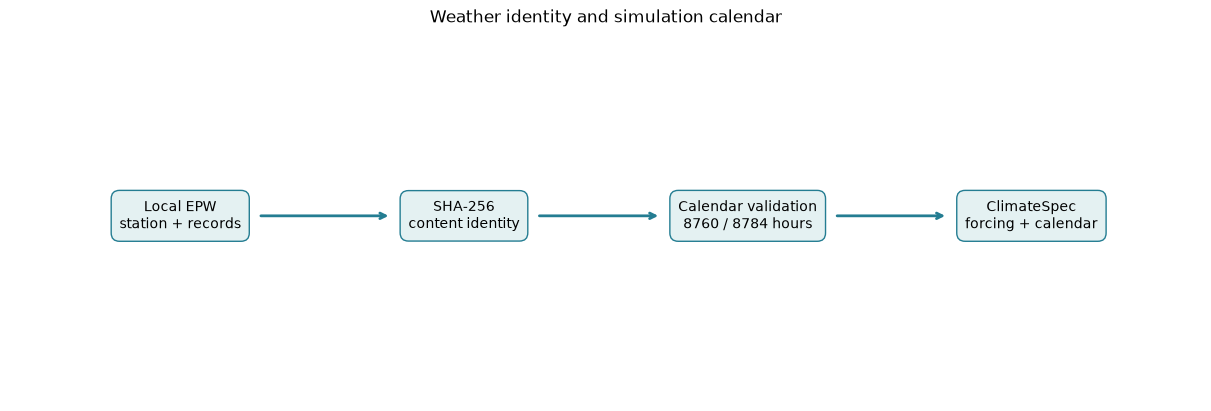

In [2]:
from demo.support.common import flow
flow(['Local EPW\nstation + records', 'SHA-256\ncontent identity', 'Calendar validation\n8760 / 8784 hours', 'ClimateSpec\nforcing + calendar'], 'Weather identity and simulation calendar', figsize=(12, 4))

## Construct the climate explicitly

The EPW file hash is part of input identity. The calendar year controls the simulation time axis and is distinct from the multi-year weather period in a TMY filename.

### Read the code and output

The equality between the file hash and `ClimateSpec.weather_sha256` checks identity. The 8760-hour assertion checks the selected non-leap calendar. These are complementary: two weather files can have the same number of records and very different temperatures, while the correct file can still be paired with an incompatible calendar.

In [3]:
from epsm_core.weather import file_sha256, hourly_axis, validate_epw_calendar
climate = climate_from_epw(epw(), calendar_year=2023)
assert isinstance(climate, ClimateSpec)
assert climate.weather_sha256 == file_sha256(epw())
table(climate.model_dump())
validate_epw_calendar(epw(), climate.calendar_year)
axis = hourly_axis(2023)
assert len(axis) == climate.hours_in_year == 8760

,field,value
0,epw_path,/Users/ssanjay/GitHub/epsm_core/data/weather/S...
1,weather_sha256,99f6df726debe1f7df19317227ced9685fa3cf9d031bd5...
2,latitude_deg,57.6761
3,longitude_deg,12.2919
4,elevation_m,155.2
5,time_zone_hours,1.0
6,calendar_year,2023


## Preview hourly weather

Read temperature and radiation fields to understand the forcing. EPW hour numbering is 1–24; use the validated package calendar for result alignment.

### Read the code and output

`weather_frame` is a plotting helper that reads a few EPW columns, not a replacement for package calendar validation. Temperature is in °C; horizontal solar data is reported as interval irradiation. In the heatmap, columns are weather days and rows are hour indices, which reveals diurnal and seasonal patterns that monthly averages conceal.

,month,day,hour,temperature_c,relative_humidity_pct,global_horizontal_wh_m2
0,1,1,1,-5.7,87,0
1,1,1,2,-3.5,90,0
2,1,1,3,-5.7,89,0
3,1,1,4,-3.8,89,0
4,1,1,5,-3.7,89,0
5,1,1,6,-3.5,88,0
6,1,1,7,-3.6,87,0
7,1,1,8,-3.8,87,0
8,1,1,9,-4.3,88,0
9,1,1,10,-4.8,85,9


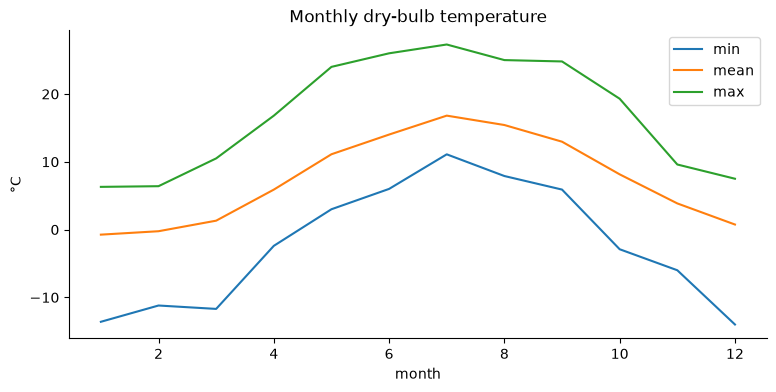

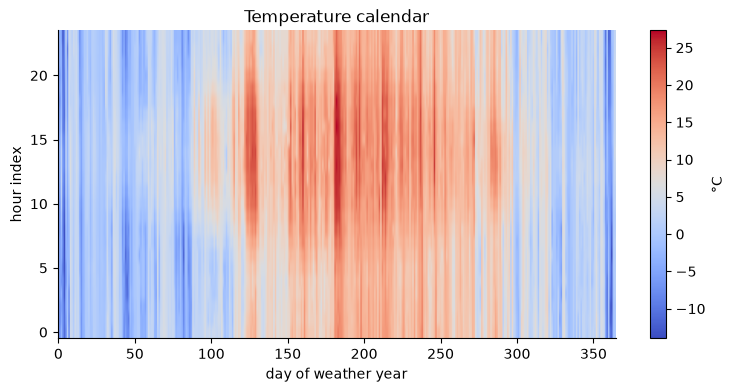

In [4]:
w = weather_frame(epw())
table(w.head(12))
fig, ax = plt.subplots(figsize=(9, 4))
w.groupby("month")["temperature_c"].agg(["min","mean","max"]).plot(ax=ax, title="Monthly dry-bulb temperature", ylabel="°C")
plt.show(); plt.close(fig)
fig, ax = plt.subplots(figsize=(9, 4))
plt.imshow(w.temperature_c.to_numpy().reshape(-1,24).T, aspect="auto", origin="lower", cmap="coolwarm")
plt.colorbar(label="°C"); plt.xlabel("day of weather year"); plt.ylabel("hour index"); plt.title("Temperature calendar"); plt.show(); plt.close(fig)

## Check calendar length

A leap-year axis has 8784 intervals. Calendar compatibility is validated rather than silently repeating or dropping a weather day.

### Read the code and output

The 8784-hour leap-year axis contains an additional day. The failure example asks whether this particular non-leap weather file can supply it. Read the validation message instead of automatically duplicating a day: doing so would change the forcing and needs a separately documented weather-preparation decision.

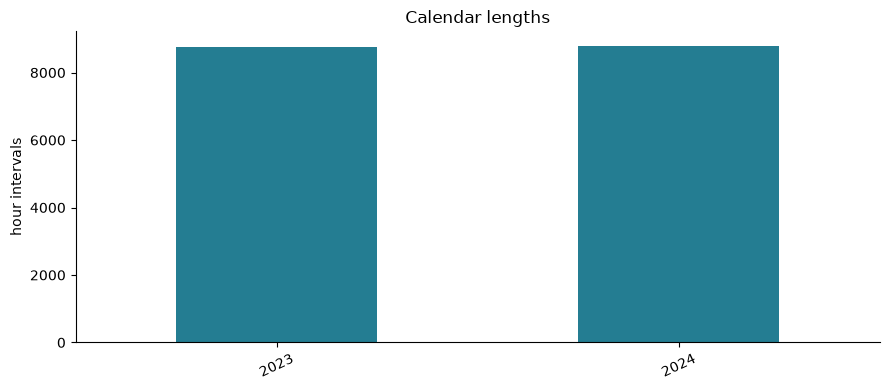

Expected incompatibility for this non-leap TMY: EPW calendar does not cover 2024 exactly (8784 hourly records)


In [5]:
assert len(hourly_axis(2024)) == 8784
bars({"2023":len(axis), "2024":len(hourly_axis(2024))}, "hour intervals", "Calendar lengths")
try:
    validate_epw_calendar(epw(), 2024)
except ValueError as error:
    print("Expected incompatibility for this non-leap TMY:", error)

## Interpretation and next experiment

Keep EPW identity, chosen calendar and result interval units together. A timestamp shift can invalidate coincident-peak comparisons even if annual totals agree.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.